# AI Client Project 3 – Retinopathy Type Detection

**Business case:** Retinopathy is damage or disease of the retina and can lead to vision problems or blindness. It is often linked to diabetes and high blood pressure.

**Project goal:** Build a model that detects the *type* of retinopathy from retina scan images, using the provided dataset (`data_all.csv` + `images/` folder).

**Approach**
1. Load data and explore it (class balance, image sizes, sample scans)
2. Preprocess images (crop black borders, resize, normalise)
3. Baseline model: hand-crafted colour/texture features + Random Forest
4. Main model: Convolutional Neural Network (CNN) with data augmentation
5. Evaluate on a held-out test set and compare the models
6. Save the model and show how to predict on a new image

## 1. Imports and configuration

In [1]:
import os, random, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
from sklearn.utils.class_weight import compute_class_weight
warnings.filterwarnings('ignore')
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

# Folder that contains data_all.csv and the images/ folder (change this path if you run elsewhere, e.g. Colab)
DATA_DIR = '.'
IMG_SIZE = 128
print('TensorFlow', tf.__version__)

I0000 00:00:1795230357.722393     441 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0


I0000 00:00:1795230359.158414     441 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## 2. Load the data

In [2]:
df = pd.read_csv(os.path.join(DATA_DIR, 'data_all.csv'))
df = df.drop(columns=['Unnamed: 0'])      # leftover index column
print(df.shape)
df.head()

(1764, 2)


,file,cat
0,o_c1t10003118.jpg,1
1,o_c1t1003016260.jpg,1
2,o_c1t1004522299.jpg,1
3,o_c1t1008823172.jpg,1
4,o_c1t1011431188.jpg,1


In [3]:
print('Missing values:\n', df.isna().sum(), '\n')
print('Duplicate file names:', df['file'].duplicated().sum())
print('All image files exist:', all(os.path.exists(os.path.join(DATA_DIR, 'images', f)) for f in df['file']))
print('\nClass counts:'); print(df['cat'].value_counts().sort_index())

Missing values:
 file    0
cat     0
dtype: int64 

Duplicate file names: 0
All image files exist: True

Class counts:
cat
1    811
2    569
3    384
Name: count, dtype: int64


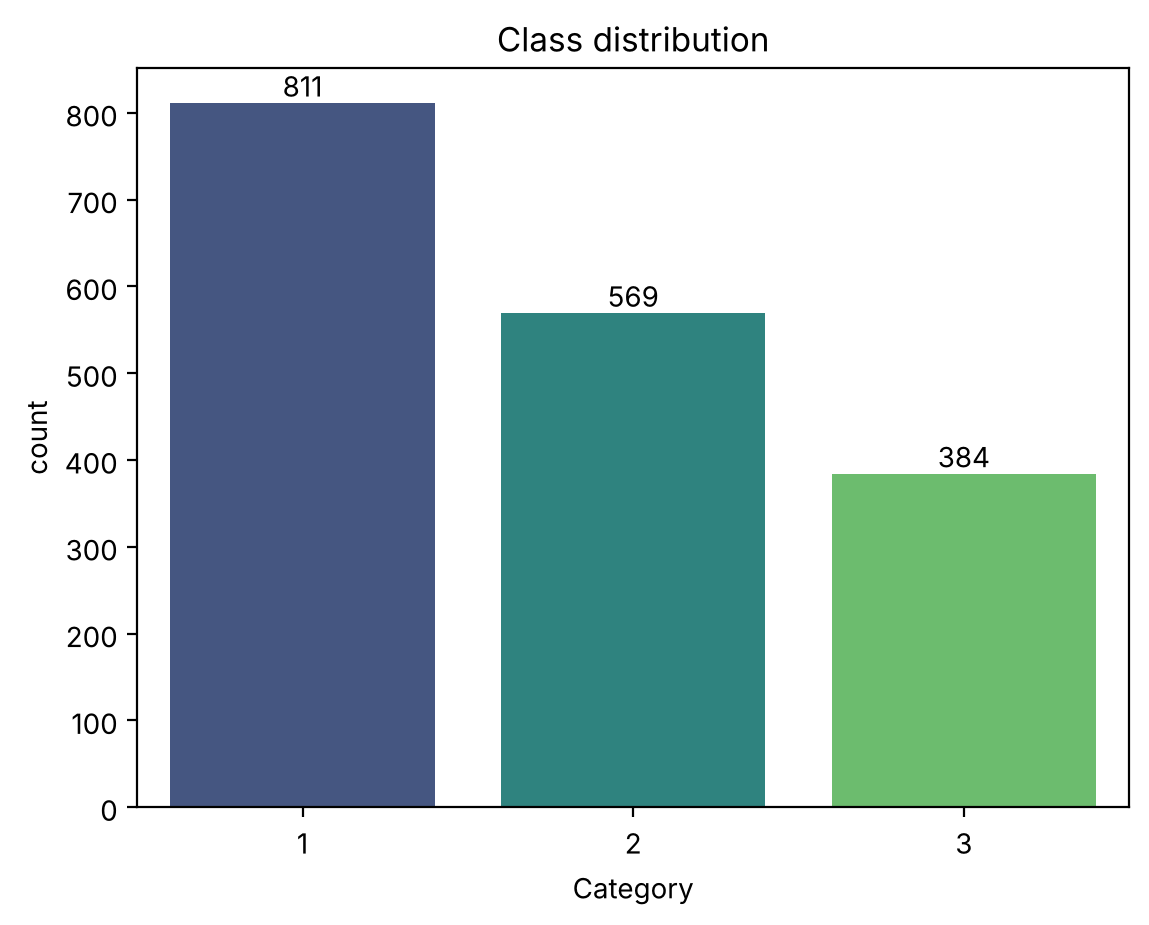

In [4]:
# The CSV gives only an encoded category (1, 2, 3); no medical names are provided, so we keep them as "Category 1/2/3".
df['label'] = df['cat'] - 1                     # 0,1,2 for the models
CLASS_NAMES = ['Category 1', 'Category 2', 'Category 3']

ax = sns.countplot(x='cat', data=df, palette='viridis')
for p in ax.patches: ax.annotate(int(p.get_height()), (p.get_x()+p.get_width()/2, p.get_height()), ha='center', va='bottom')
plt.title('Class distribution'); plt.xlabel('Category'); plt.show()

The classes are **imbalanced** (Category 1 is about twice as large as Category 3), so we will use stratified splits, class weights, and look at per-class metrics (not just accuracy).

## 3. Look at the images

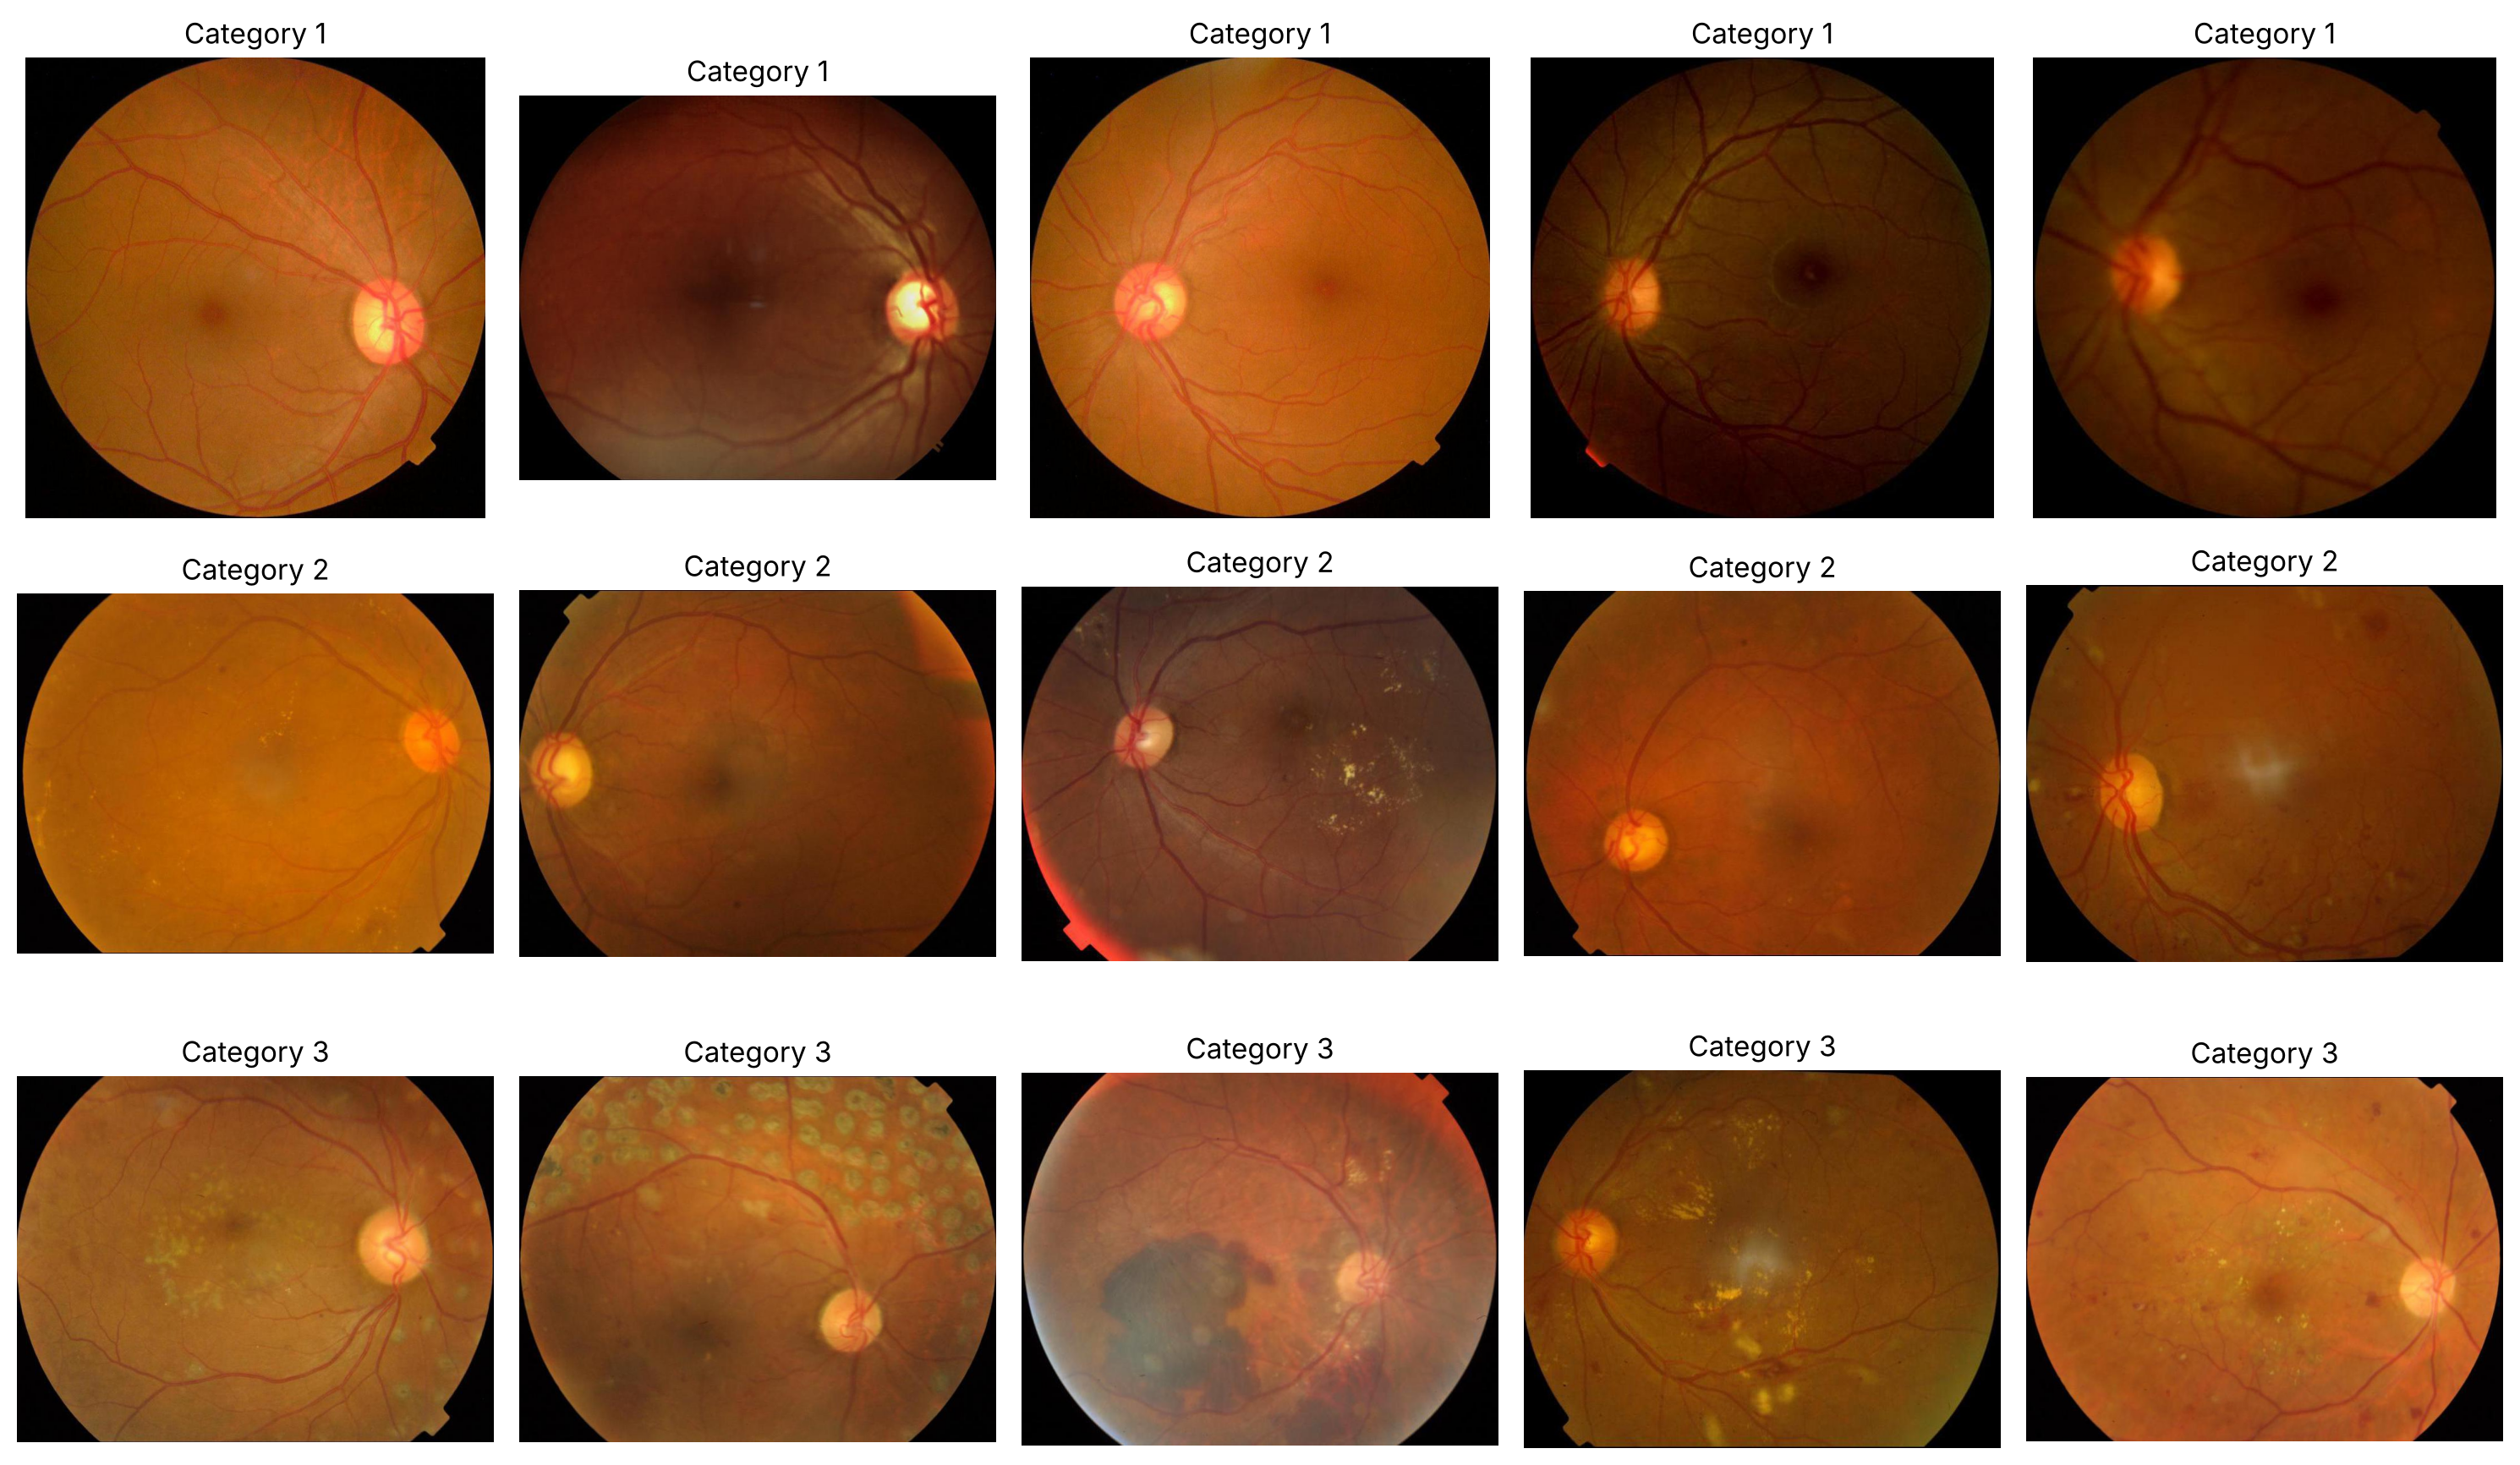

In [5]:
fig, axes = plt.subplots(3, 5, figsize=(15, 9))
for i, c in enumerate([1, 2, 3]):
    files = df[df['cat'] == c]['file'].sample(5, random_state=1)
    for j, f in enumerate(files):
        axes[i, j].imshow(Image.open(os.path.join(DATA_DIR, 'images', f)))
        axes[i, j].set_title(f'Category {c}'); axes[i, j].axis('off')
plt.tight_layout(); plt.show()

In [6]:
sizes = [Image.open(os.path.join(DATA_DIR, 'images', f)).size for f in df['file'].sample(300, random_state=0)]
sz = pd.DataFrame(sizes, columns=['width', 'height'])
print(sz.describe().loc[['min', 'mean', 'max']])

           width      height
min   604.000000  543.000000
mean  826.206667  710.823333
max   899.000000  900.000000


Images are retina photographs of different sizes with black borders around the circular scan, so we crop the borders and resize everything to a fixed size.

## 4. Preprocessing

In [7]:
def load_image(path, size=IMG_SIZE):
    img = Image.open(path).convert('RGB')
    arr = np.asarray(img)
    mask = arr.max(axis=2) > 25                       # non-black pixels
    if mask.any():
        ys, xs = np.where(mask)
        arr = arr[ys.min():ys.max()+1, xs.min():xs.max()+1]   # crop black border
    return np.asarray(Image.fromarray(arr).resize((size, size), Image.BILINEAR), dtype=np.uint8)

cache = os.path.join(DATA_DIR, f'images_{IMG_SIZE}.npy')
if os.path.exists(cache):
    X = np.load(cache)
else:
    X = np.stack([load_image(os.path.join(DATA_DIR, 'images', f)) for f in df['file']])
    np.save(cache, X)
y = df['label'].values
print(X.shape, X.dtype, y.shape)

(1764, 128, 128, 3) uint8 (1764,)


In [8]:
# 70% train / 15% validation / 15% test, stratified so every split keeps the class ratio
idx = np.arange(len(df))
tr_idx, tmp_idx = train_test_split(idx, test_size=0.30, stratify=y, random_state=SEED)
va_idx, te_idx  = train_test_split(tmp_idx, test_size=0.50, stratify=y[tmp_idx], random_state=SEED)
X_tr, y_tr, X_va, y_va, X_te, y_te = X[tr_idx], y[tr_idx], X[va_idx], y[va_idx], X[te_idx], y[te_idx]
for n, yy in [('train', y_tr), ('val', y_va), ('test', y_te)]:
    print(n, len(yy), np.bincount(yy))

train 1234 [567 398 269]
val 265 [122  85  58]
test 265 [122  86  57]


## 5. Baseline model: hand-crafted features + Random Forest
Before using a deep network we build a simple baseline. For each image we compute colour statistics and colour histograms (RGB and HSV) plus simple texture/edge measures. Lesions such as haemorrhages and exudates change the colour distribution of the retina, so even these simple features carry signal.

In [9]:
from skimage.color import rgb2hsv
from skimage.filters import sobel

def features(img):
    f = []
    hsv = rgb2hsv(img)
    for space in (img.astype(np.float32)/255.0, hsv):
        for ch in range(3):
            v = space[..., ch].ravel()
            v = v[img.max(axis=2).ravel() > 25]               # ignore black background
            f += [v.mean(), v.std(), *np.percentile(v, [5, 25, 50, 75, 95])]
            f += list(np.histogram(v, bins=8, range=(0, 1))[0] / max(len(v), 1))
    g = img[..., 1].astype(np.float32) / 255.0                # green channel shows vessels/lesions best
    e = sobel(g)
    f += [e.mean(), e.std(), *np.percentile(e, [50, 90, 99])]
    return f

F = np.array([features(im) for im in X])
print('Feature matrix:', F.shape)

Feature matrix: (1764, 95)


In [10]:
rf = RandomForestClassifier(n_estimators=400, class_weight='balanced', random_state=SEED, n_jobs=-1)
rf.fit(F[tr_idx], y_tr)
rf_pred = rf.predict(F[te_idx])
print('Random Forest – test accuracy: %.3f | macro F1: %.3f' % (accuracy_score(y_te, rf_pred), f1_score(y_te, rf_pred, average='macro')))
print(classification_report(y_te, rf_pred, target_names=CLASS_NAMES))

Random Forest – test accuracy: 0.732 | macro F1: 0.681
              precision    recall  f1-score   support

  Category 1       0.90      0.93      0.91       122
  Category 2       0.64      0.59      0.61        86
  Category 3       0.51      0.53      0.52        57

    accuracy                           0.73       265
   macro avg       0.68      0.68      0.68       265
weighted avg       0.73      0.73      0.73       265



## 6. Main model: CNN with data augmentation
A small CNN is trained from scratch on the 128×128 images. Augmentation (flips, rotation, zoom, brightness/contrast) reduces over-fitting on this small dataset, class weights compensate for the imbalance, and early stopping keeps the best epoch.

In [11]:
def make_cnn():
    aug = keras.Sequential([
        layers.RandomFlip('horizontal_and_vertical'),
        layers.RandomRotation(0.15),
        layers.RandomZoom(0.1),
        layers.RandomBrightness(0.15, value_range=(0, 1)),
        layers.RandomContrast(0.15),
    ], name='augmentation')
    inp = keras.Input((IMG_SIZE, IMG_SIZE, 3))
    x = layers.Rescaling(1/255.)(inp)
    x = aug(x)
    for filters in (32, 64, 128, 128):
        x = layers.Conv2D(filters, 3, padding='same', use_bias=False)(x)
        x = layers.BatchNormalization(momentum=0.9)(x); x = layers.Activation('relu')(x)
        x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(64, activation='relu')(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(3, activation='softmax')(x)
    return keras.Model(inp, out)

model = make_cnn()
model.compile(optimizer=keras.optimizers.Adam(1e-3), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 250,339 (977.89 KB)

 Trainable params: 249,635 (975.14 KB)

 Non-trainable params: 704 (2.75 KB)

In [12]:
cw = compute_class_weight('balanced', classes=np.unique(y_tr), y=y_tr)
class_weight = dict(enumerate(cw)); print('Class weights:', class_weight)

callbacks = [
    keras.callbacks.EarlyStopping(monitor='val_accuracy', mode='max', patience=10, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-5),
]
history = model.fit(X_tr, y_tr, validation_data=(X_va, y_va), epochs=EPOCHS if 'EPOCHS' in globals() else 35,
                    batch_size=32, class_weight=class_weight, callbacks=callbacks, verbose=2)

Class weights: {0: np.float64(0.7254556143445032), 1: np.float64(1.033500837520938), 2: np.float64(1.5291201982651796)}


Epoch 1/35


39/39 - 34s - 862ms/step - accuracy: 0.4425 - loss: 1.2541 - val_accuracy: 0.2679 - val_loss: 1.2413 - learning_rate: 0.0010


Epoch 2/35


39/39 - 40s - 1s/step - accuracy: 0.5008 - loss: 1.0350 - val_accuracy: 0.5887 - val_loss: 0.7887 - learning_rate: 0.0010


Epoch 3/35


... (33 outputs left out)

Epoch 20/35


39/39 - 41s - 1s/step - accuracy: 0.6734 - loss: 0.7066 - val_accuracy: 0.6792 - val_loss: 0.6603 - learning_rate: 2.5000e-04


Epoch 21/35


39/39 - 42s - 1s/step - accuracy: 0.6759 - loss: 0.6909 - val_accuracy: 0.6528 - val_loss: 0.6958 - learning_rate: 2.5000e-04


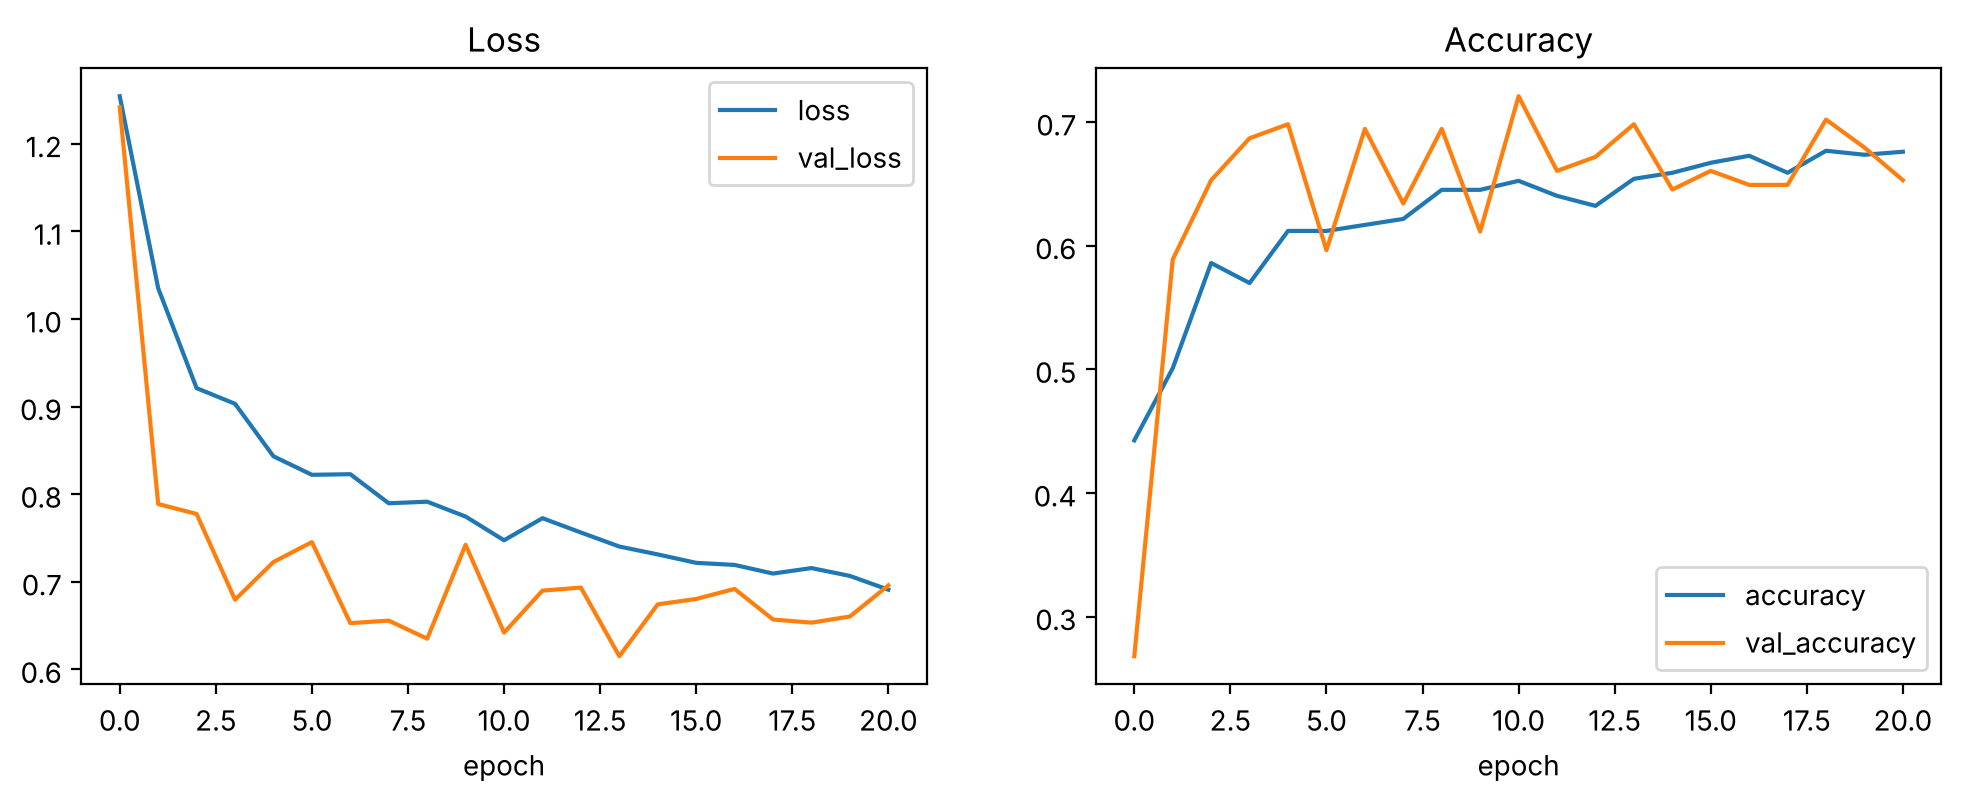

In [13]:
h = pd.DataFrame(history.history)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
h[['loss', 'val_loss']].plot(ax=ax[0], title='Loss'); h[['accuracy', 'val_accuracy']].plot(ax=ax[1], title='Accuracy')
for a in ax: a.set_xlabel('epoch')
plt.show()

## 7. Evaluation on the test set

CNN – test accuracy: 0.740 | macro F1: 0.688
              precision    recall  f1-score   support

  Category 1       0.84      0.97      0.90       122
  Category 2       0.75      0.48      0.58        86
  Category 3       0.53      0.65      0.58        57

    accuracy                           0.74       265
   macro avg       0.71      0.70      0.69       265
weighted avg       0.74      0.74      0.73       265



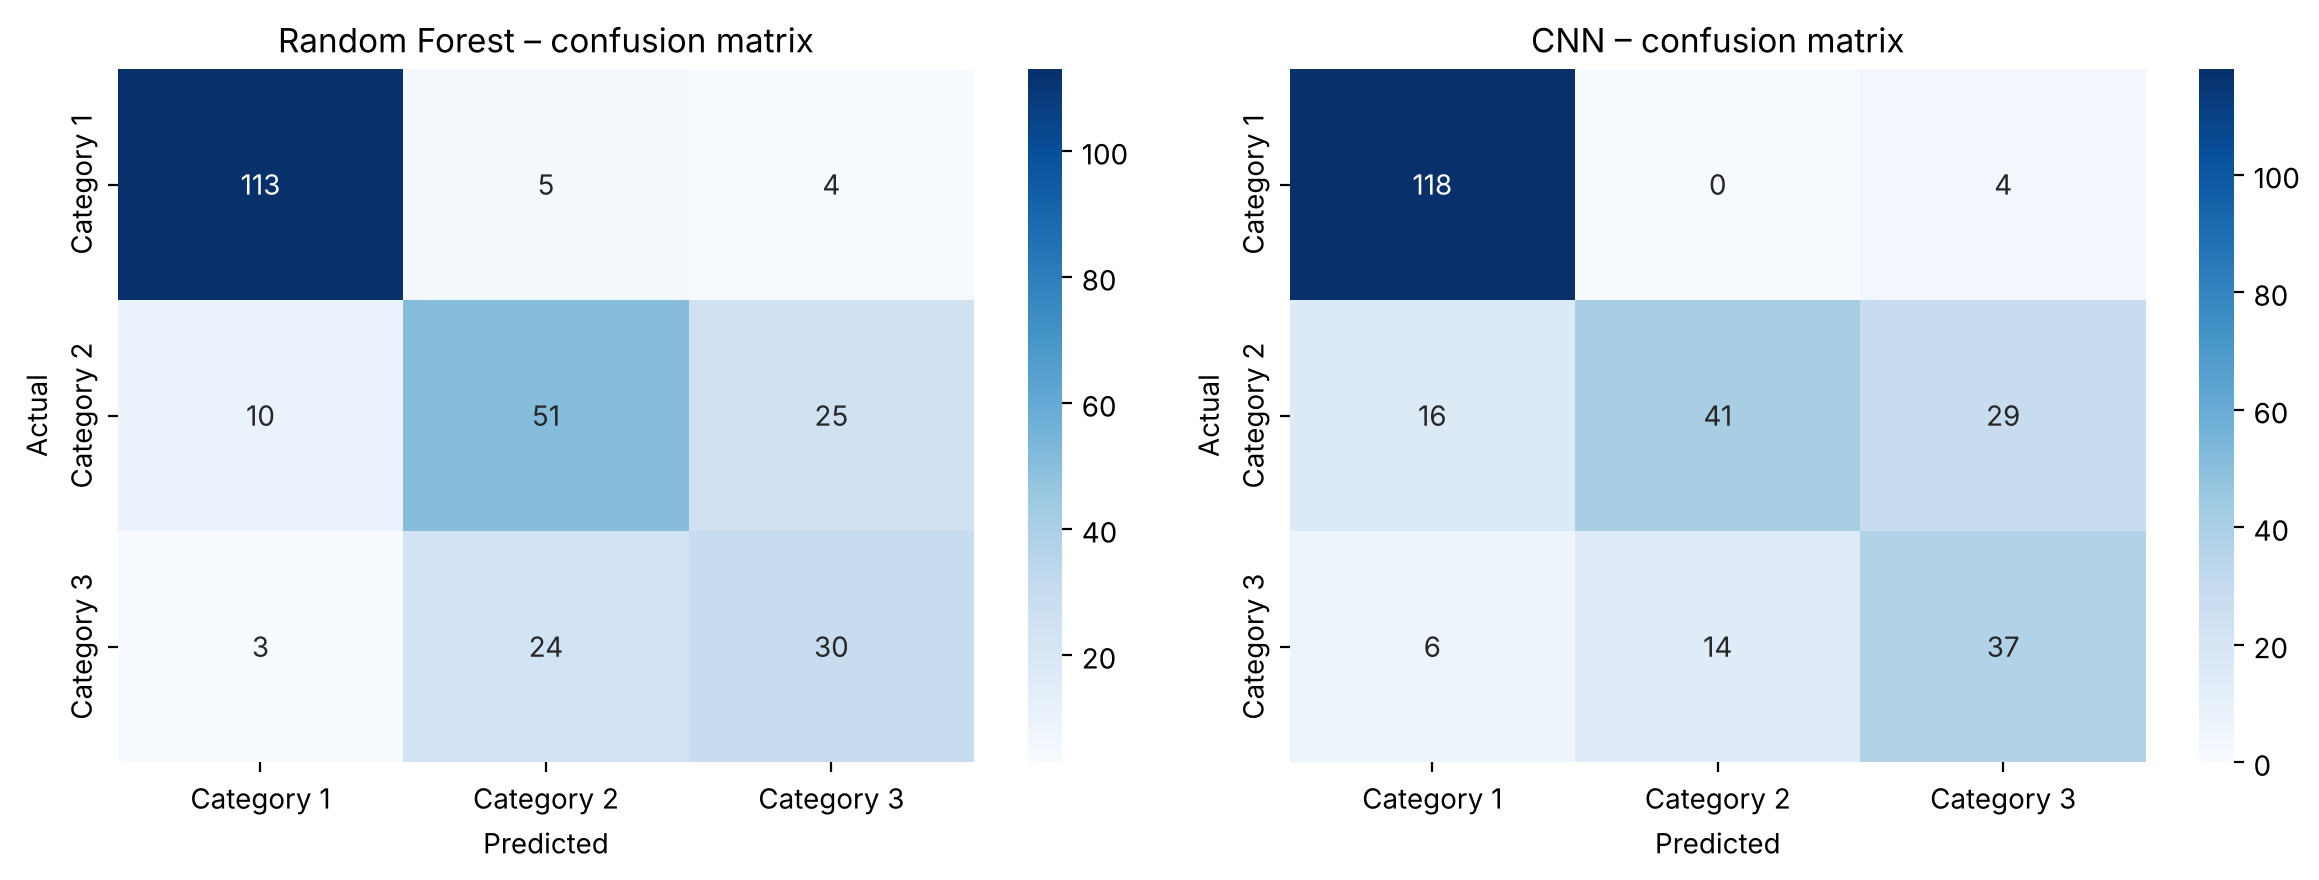

In [14]:
cnn_prob = model.predict(X_te, verbose=0)
cnn_pred = cnn_prob.argmax(1)
print('CNN – test accuracy: %.3f | macro F1: %.3f' % (accuracy_score(y_te, cnn_pred), f1_score(y_te, cnn_pred, average='macro')))
print(classification_report(y_te, cnn_pred, target_names=CLASS_NAMES))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for a, (name, p) in zip(ax, [('Random Forest', rf_pred), ('CNN', cnn_pred)]):
    sns.heatmap(confusion_matrix(y_te, p), annot=True, fmt='d', cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=a)
    a.set_title(f'{name} – confusion matrix'); a.set_xlabel('Predicted'); a.set_ylabel('Actual')
plt.tight_layout(); plt.show()

In [15]:
comparison = pd.DataFrame({
    'Model': ['Random Forest (features)', 'CNN (augmentation)'],
    'Accuracy': [accuracy_score(y_te, rf_pred), accuracy_score(y_te, cnn_pred)],
    'Macro F1': [f1_score(y_te, rf_pred, average='macro'), f1_score(y_te, cnn_pred, average='macro')],
}).round(3)
comparison

,Model,Accuracy,Macro F1
0,Random Forest (features),0.732,0.681
1,CNN (augmentation),0.740,0.688


## 8. Save the model and predict on a new image

Actual: Category 1


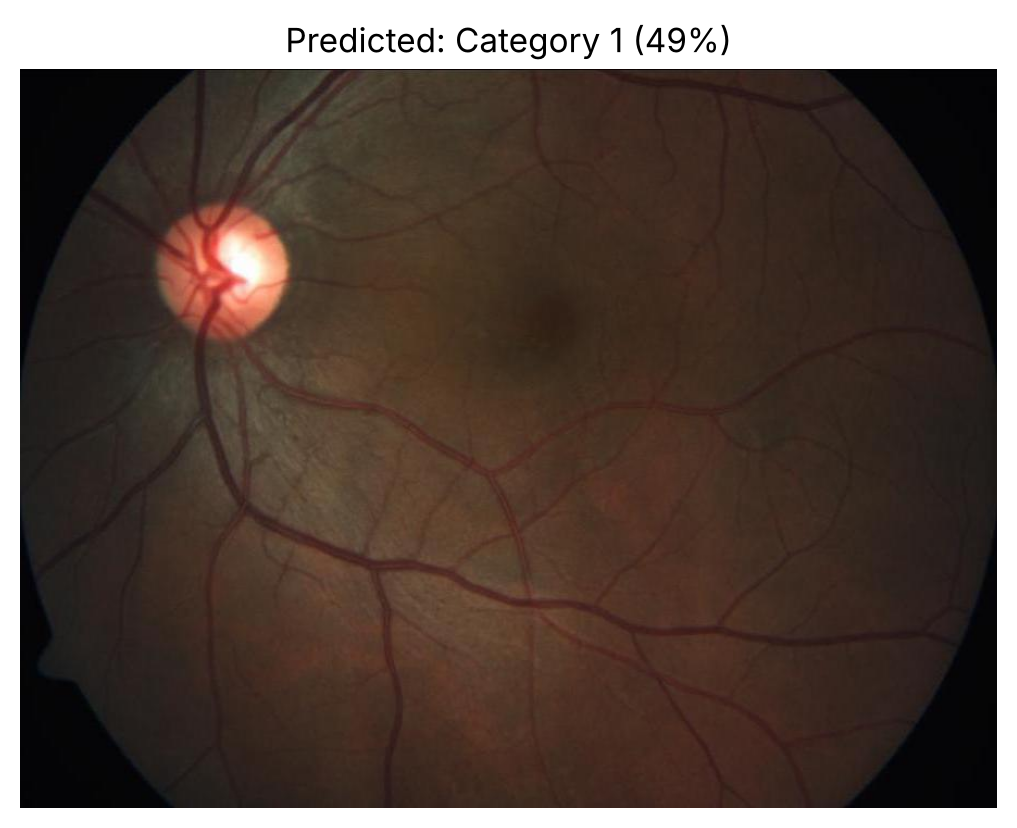

{'Category 1': np.float32(0.485),
 'Category 2': np.float32(0.241),
 'Category 3': np.float32(0.274)}

In [16]:
model.save(os.path.join(DATA_DIR, 'retinopathy_cnn.keras'))

def predict_image(path):
    arr = load_image(path)[None, ...]
    p = model.predict(arr, verbose=0)[0]
    plt.imshow(Image.open(path)); plt.axis('off')
    plt.title(f'Predicted: {CLASS_NAMES[p.argmax()]} ({p.max():.0%})'); plt.show()
    return dict(zip(CLASS_NAMES, p.round(3)))

sample = df.iloc[te_idx[0]]
print('Actual:', CLASS_NAMES[sample['label']])
predict_image(os.path.join(DATA_DIR, 'images', sample['file']))

## 9. Conclusion

| Model | Test accuracy | Macro F1 |
|---|---|---|
| Random Forest (hand-crafted features) | 0.732 | 0.681 |
| CNN with augmentation | 0.740 | 0.688 |

- Both models reach roughly **73-74% accuracy** on 265 unseen test images, so the CNN is only marginally better than the baseline (a difference of 2 images on this test set, not a meaningful gap).
- **Category 1** is detected well by both models (F1 about 0.90). **Category 2 and Category 3 are much harder** (F1 about 0.52-0.61). The CNN misses many Category 2 images (recall 0.48), while Category 3 is the smallest class.
- Limits: the CNN is trained from scratch on only 1,234 images at 128x128 and was not tuned further. A pretrained network (ResNet/EfficientNet fine-tuning) on a GPU, higher resolution and cross-validation are the most promising next steps and would likely improve Category 2/3.
- This is a learning project; it is not a validated medical diagnostic tool.